<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/gg_lockup.png" alt="Global Gateway · European Union" height="64"/>

**Funded by the European Union** · Africa–EU Space Partnership Programme · Strengthening Early Warnings for Africa (SEWA)

# Desert dust over West Africa with CAMS 🏜️
### Copernicus Atmosphere Monitoring Service · free account

🌐 [English](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams.ipynb) · [Français](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams_fr.ipynb) · [Português](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams_pt.ipynb)

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/piddy376/visits-weather-notebooks/blob/main/senegal/dust_cams.ipynb)

In the dry season, roughly November to March, the north-easterly **Harmattan** carries Saharan dust across the
Sahel towards the Atlantic. This notebook maps the dust forecast from the **CAMS global forecast**, run by ECMWF for
the European Union, from yesterday's run up to five days ahead.

**What you need:** a Google account (to use Colab) and a free Copernicus account (step below). Everything runs on Google's computers: the data is downloaded there, not to your phone
or laptop, so a slow or mobile connection is fine.

| Data | What this notebook uses | Licence |
|---|---|---|
| CAMS global atmospheric composition forecast, about 40 km | Dust aerosol optical depth at 550 nm | Copernicus licence, free |

**Tools:** [earthkit](https://earthkit.ecmwf.int), ECMWF's free, open-source Python tools for weather and climate data.

*Press **Runtime → Run all**. The data store queues requests, so step 2 can take a few minutes.*

<img src="https://raw.githubusercontent.com/piddy376/visits-weather-notebooks/main/assets/cams_logoline_pos.png" alt="Copernicus, implemented by ECMWF" height="30"/>

In [ ]:
# Install the open-source tools (Colab / fresh machine). Takes a few minutes the first time.
%pip install -q "earthkit-data[cds]" earthkit-plots

## Your free Copernicus key

Copernicus data is free and open, but the data stores ask you to register once so they can manage the queue:
1. Create an account at [cds.climate.copernicus.eu](https://cds.climate.copernicus.eu) (the same login works for the
   Atmosphere Data Store).
2. Open the [dataset page](https://ads.atmosphere.copernicus.eu/datasets/cams-global-atmospheric-composition-forecasts?tab=download) on the Atmosphere Data Store and accept its licence (bottom of the Download tab). You only do this once.
3. Copy your API key from your [profile page](https://cds.climate.copernicus.eu/profile) and paste it below.

**Use your own key.** Everyone who runs this notebook needs their own free Copernicus account and key. The next cell asks
for it in a hidden box and saves it on the machine running the notebook (in Colab that is a temporary machine, wiped when
you close the tab). The key is never stored in the notebook, so don't paste it into a code cell, and don't share a notebook
or screenshot that shows it. On your own computer with `~/.cdsapirc` / `~/.adsapirc` already in place, the cell asks nothing.

In [2]:
import os
from getpass import getpass
rc = {"~/.cdsapirc": "https://cds.climate.copernicus.eu/api", "~/.adsapirc": "https://ads.atmosphere.copernicus.eu/api"}
missing = [p for p in rc if not os.path.exists(os.path.expanduser(p))]
if missing:
    key = getpass("Copernicus API key: ")
    for p in missing:
        with open(os.path.expanduser(p), "w") as f:
            f.write(f"url: {rc[p]}\nkey: {key}\n")
print("Copernicus key ready")

Copernicus key ready


In [3]:
import pyproj                     # import before earthkit.data (avoids a crash at exit)
import datetime as dt
import earthkit.data as ekd
import earthkit.plots as ekp
import cartopy.crs as ccrs
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
import numpy as np

## 1 · Choose the run, the lead time and the area

In [4]:
AREA = [27.0, -26.0, 4.0, 10.0]                                   # north, west, south, east
DATE = (dt.date.today() - dt.timedelta(days=1)).isoformat()      # yesterday's run is always complete
LEAD = 72                                                         # hours after 00 UTC, up to 120
CITIES = [("Dakar", 14.716, -17.467), ("Saint-Louis", 16.018, -16.489), ("Touba", 14.850, -15.883),
          ("Tambacounda", 13.771, -13.667), ("Ziguinchor", 12.583, -16.272), ("Kédougou", 12.557, -12.174)]

def label_cities(ax):
    for name, la, lo in CITIES:
        ax.scatter([lo], [la], s=36, color="#ffd23f", edgecolors="#1a1a1a", linewidths=0.8, zorder=10,
                   transform=ccrs.PlateCarree())
        ax.text(lo, la, f"  {name}", transform=ccrs.PlateCarree(), fontsize=10, fontweight="bold", zorder=11,
                color="#1d2230", path_effects=[pe.withStroke(linewidth=2.5, foreground="white")])

## 2 · Get the dust forecast

In [5]:
cams = ekd.from_source("ads", "cams-global-atmospheric-composition-forecasts", {
    "variable": "dust_aerosol_optical_depth_550nm", "date": f"{DATE}/{DATE}", "time": "00:00",
    "type": "forecast", "leadtime_hour": str(LEAD), "area": AREA, "data_format": "grib"}).to_xarray()
duaod = cams[list(cams.data_vars)[0]].squeeze()
valid = dt.datetime.fromisoformat(DATE) + dt.timedelta(hours=LEAD)
print(f"Dust optical depth up to {float(duaod.max()):.2f} at {valid:%A %d %B %H}:00 UTC")

Dust optical depth up to 0.44 at Sunday 22 November 00:00 UTC


## 3 · Map it

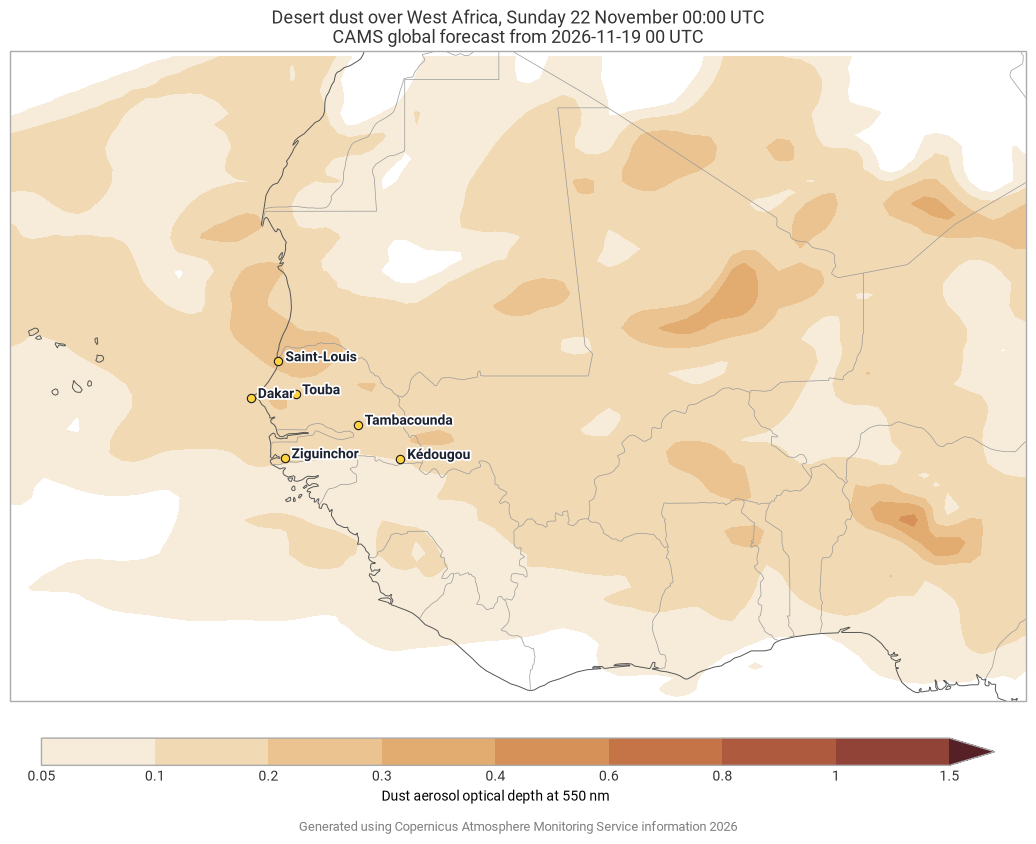

In [6]:
colors = ["#f6ecd9", "#efd3a8", "#e6b77d", "#d9955a", "#c27046", "#a34f3c", "#7d3533", "#562126"]
style = ekp.styles.Style(levels=[0.05, 0.1, 0.2, 0.3, 0.4, 0.6, 0.8, 1.0, 1.5], colors=colors, extend="max")
chart = ekp.Map(domain=[AREA[1], AREA[3], AREA[2], AREA[0]], figsize=(12, 8))
chart.contourf(duaod, style=style)
chart.coastlines(linewidth=0.7); chart.borders(linewidth=0.5)
label_cities(chart.ax)
chart.legend(label="Dust aerosol optical depth at 550 nm")
chart.title(f"Desert dust over West Africa, {valid:%A %d %B %H}:00 UTC\nCAMS global forecast from {DATE} 00 UTC", fontsize=13)
chart.attribution("Generated using Copernicus Atmosphere Monitoring Service information 2026")
chart.save("dust_cams.png")
chart.show()

## 4 · Your turn 🌍

- **Step through the week:** change `LEAD` from 0 to 120 in steps of 3.
- **Dust near the ground:** variable `"dust_aerosol_0.9-20um_mixing_ratio"` is the coarse dust; or try
  `"particulate_matter_10um"` (multiply by 1e9 for µg/m³), which is mostly dust in the Sahel dry season.
- CAMS global runs at about 40 km: it shows where the dust goes, not individual towns.

### Data & licence
Copernicus data is free and open under the Copernicus licence (CC-BY 4.0). Credit:
*Generated using Copernicus Atmosphere Monitoring Service information 2026.* ECMWF runs the Copernicus Atmosphere Monitoring Service and the
Copernicus Climate Change Service for the European Union.

[Climate Data Store](https://cds.climate.copernicus.eu) · [Atmosphere Data Store](https://ads.atmosphere.copernicus.eu) ·
[earthkit](https://earthkit.ecmwf.int)